# Лабораторная работа 5: тематическое моделирование и кластеризация

Два задания из лекции 6: тематическое моделирование корпусов, собранных в практике 2,
и кластеризация городов по кулинарным предпочтениям.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display

LAB = Path.cwd()
if not (LAB / "topic_modeling.py").exists() and (LAB / "lab5" / "topic_modeling.py").exists():
    LAB = LAB / "lab5"
sys.path.insert(0, str(LAB))

OUTPUT = LAB / "output"
DATA = LAB.parent / "lab4" / "output"

def run(*command, tail=None):
    print("$", " ".join(str(part) for part in command))
    result = subprocess.run([sys.executable, *[str(part) for part in command]],
                            cwd=LAB, capture_output=True, text=True,
                            encoding="utf-8", errors="replace")
    lines = (result.stdout + result.stderr).splitlines()
    shown = lines[-tail:] if tail else lines
    print("\n".join(shown))

    problems = [line for line in lines
                if ("Error" in line or "Traceback" in line) and line not in shown]
    if problems:
        print("\nОшибки из полного вывода:")
        print("\n".join(problems[:10]))
    return result.returncode

def show(name, width=1000):
    path = OUTPUT / name
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print("нет файла", path.name)

print("Рабочая папка:", LAB)
print("Данные практики 2:", DATA, "—", "найдены" if DATA.exists() else "НЕ НАЙДЕНЫ")
for package in ("gensim", "sklearn", "pymorphy3", "wordcloud"):
    module = __import__(package)
    print(f"{package:12} {getattr(module, '__version__', 'ok')}")

Рабочая папка: /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab5
Данные практики 2: /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab4/output — найдены


gensim       4.4.0


sklearn      1.9.1
pymorphy3    2.0.6
wordcloud    1.9.6


---
## Тесты

Сеть не нужна: модели проверяются на маленьком корпусе, кластеризация — на городах
с заранее известной кухней.

In [2]:
run("-m", "pytest", "test_lab5.py", "-q", tail=8)

$ -m pytest test_lab5.py -q


=============================== warnings summary ===============================
test_lab5.py::test_three_methods_find_the_same_culinary_groups
test_lab5.py::test_top_dishes_describe_the_cluster
  /usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
21 passed, 2 warnings in 2.15s


0

---
# Задание 1: тематическое моделирование

## Предобработка

Документ новости — заголовок и краткое описание, документ товара — название и описание
с карточки. Слова приводятся к леммам, стоп-слова и слова короче трёх букв выбрасываются.

In [3]:
import preprocess

for name in ("news", "products", "mixed"):
    documents, stats = preprocess.prepare(name, DATA)
    lengths = sorted(len(document["tokens"]) for document in documents)
    middle = lengths[len(lengths) // 2] if lengths else 0
    print(f"{name:9} загружено {stats['loaded']:4}, отброшено коротких {stats['dropped']:3}, "
          f"в работе {stats['kept']:4}, медиана длины {middle:3} слов")

news      загружено  121, отброшено коротких   0, в работе  121, медиана длины  62 слов
products  загружено  138, отброшено коротких  79, в работе   59, медиана длины   7 слов
mixed     загружено  259, отброшено коротких  79, в работе  180, медиана длины  44 слов


In [4]:
documents, _ = preprocess.prepare("news", DATA)
print("Пример документа:")
print(" ", documents[0]["title"][:80])
print(" леммы:", " ".join(documents[0]["tokens"][:20]))

Пример документа:
  Вечер на код и месяц на всё остальное: свой MCP-сервер
 леммы: вечер код месяц остальной mcp сервер продукт mcp сервер написание проверка код занять вечер писать агент остальной оказаться решение состав


## Подбор числа тем по coherence

Перебираем K от 3 до 20, для каждого считаем c_v и берём максимум.

In [5]:
run("topic_modeling.py", "--dataset", "news", "--method", "both",
    "--topics", "auto", "--compare", "--output", "news_auto", tail=14)

$ topic_modeling.py --dataset news --method both --topics auto --compare --output news_auto


  сравнение: выше coherence у NMF (0.4712)
Результаты: /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab5/output
  news_auto_coherence_lda.png
  news_auto_coherence_nmf.png
  news_auto_compare.png
  news_auto_documents_lda.csv
  news_auto_documents_lda.png
  news_auto_documents_nmf.csv
  news_auto_documents_nmf.png
  news_auto_topics.json
  news_auto_topwords_lda.png
  news_auto_topwords_nmf.png
  news_auto_wordcloud_lda.png
  news_auto_wordcloud_nmf.png


0

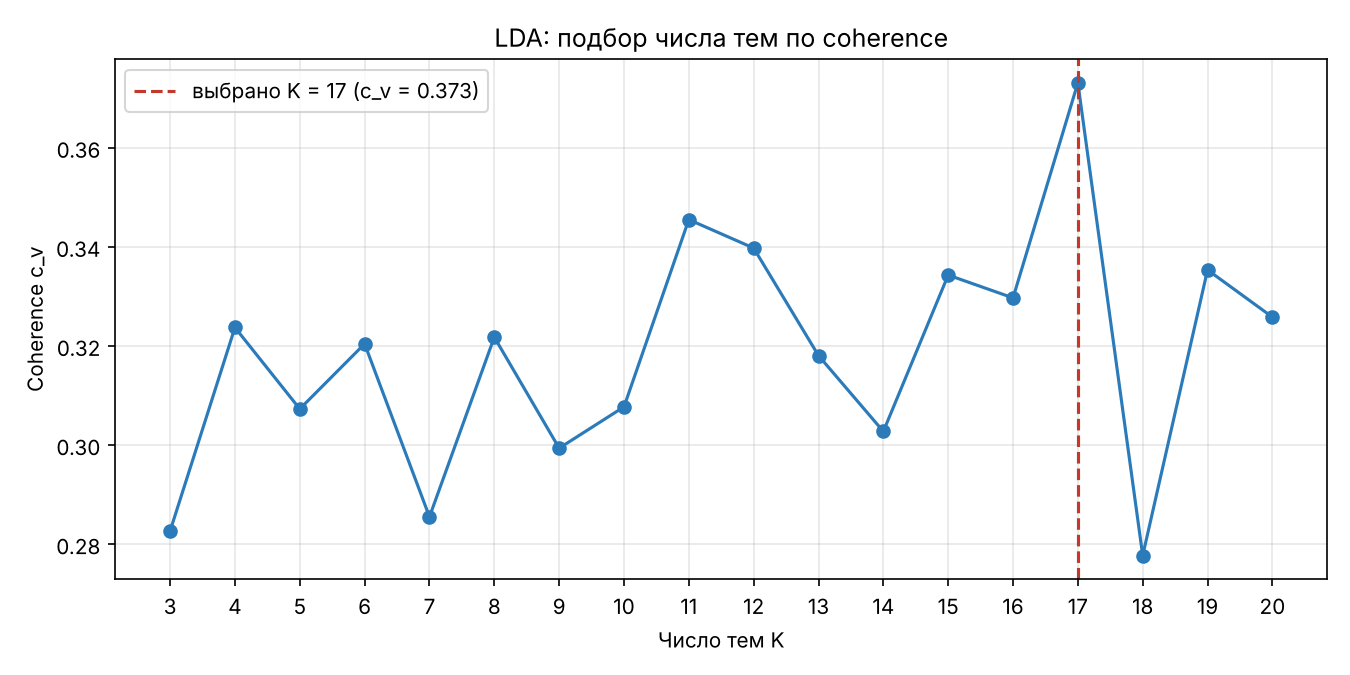

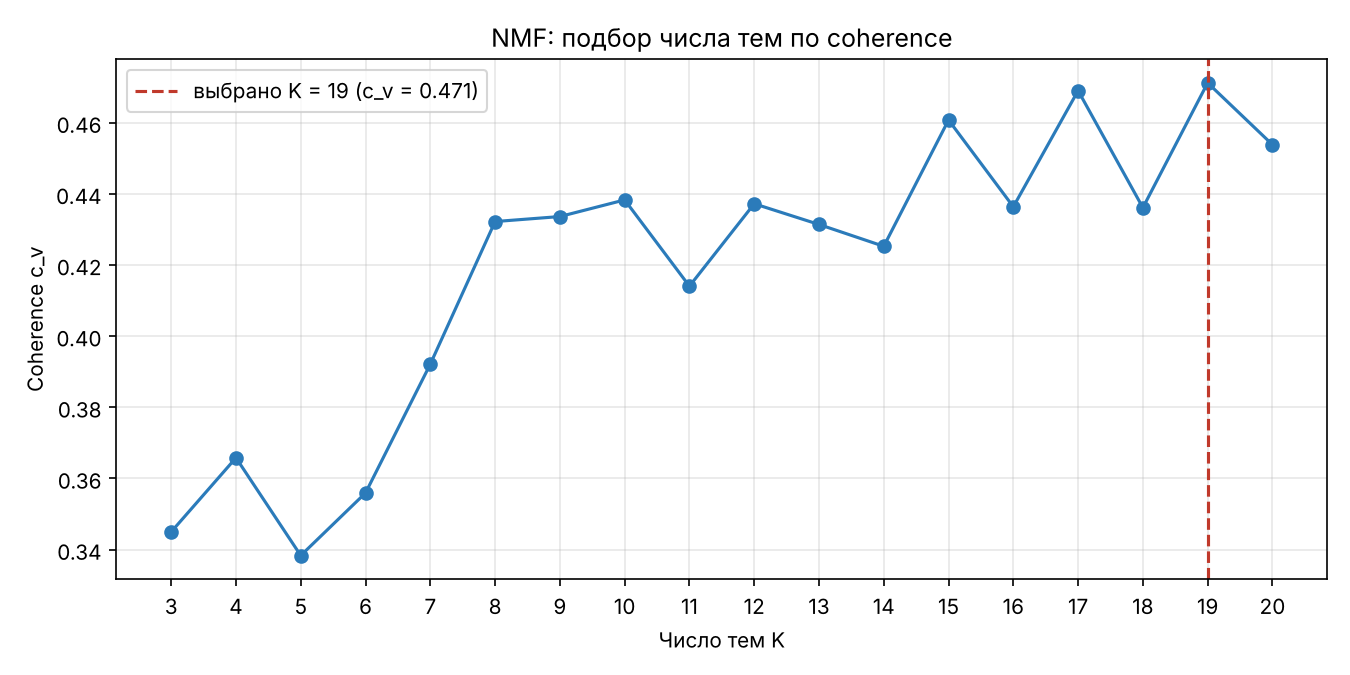

In [6]:
show("news_auto_coherence_lda.png")
show("news_auto_coherence_nmf.png")

Темы, найденные каждым методом:

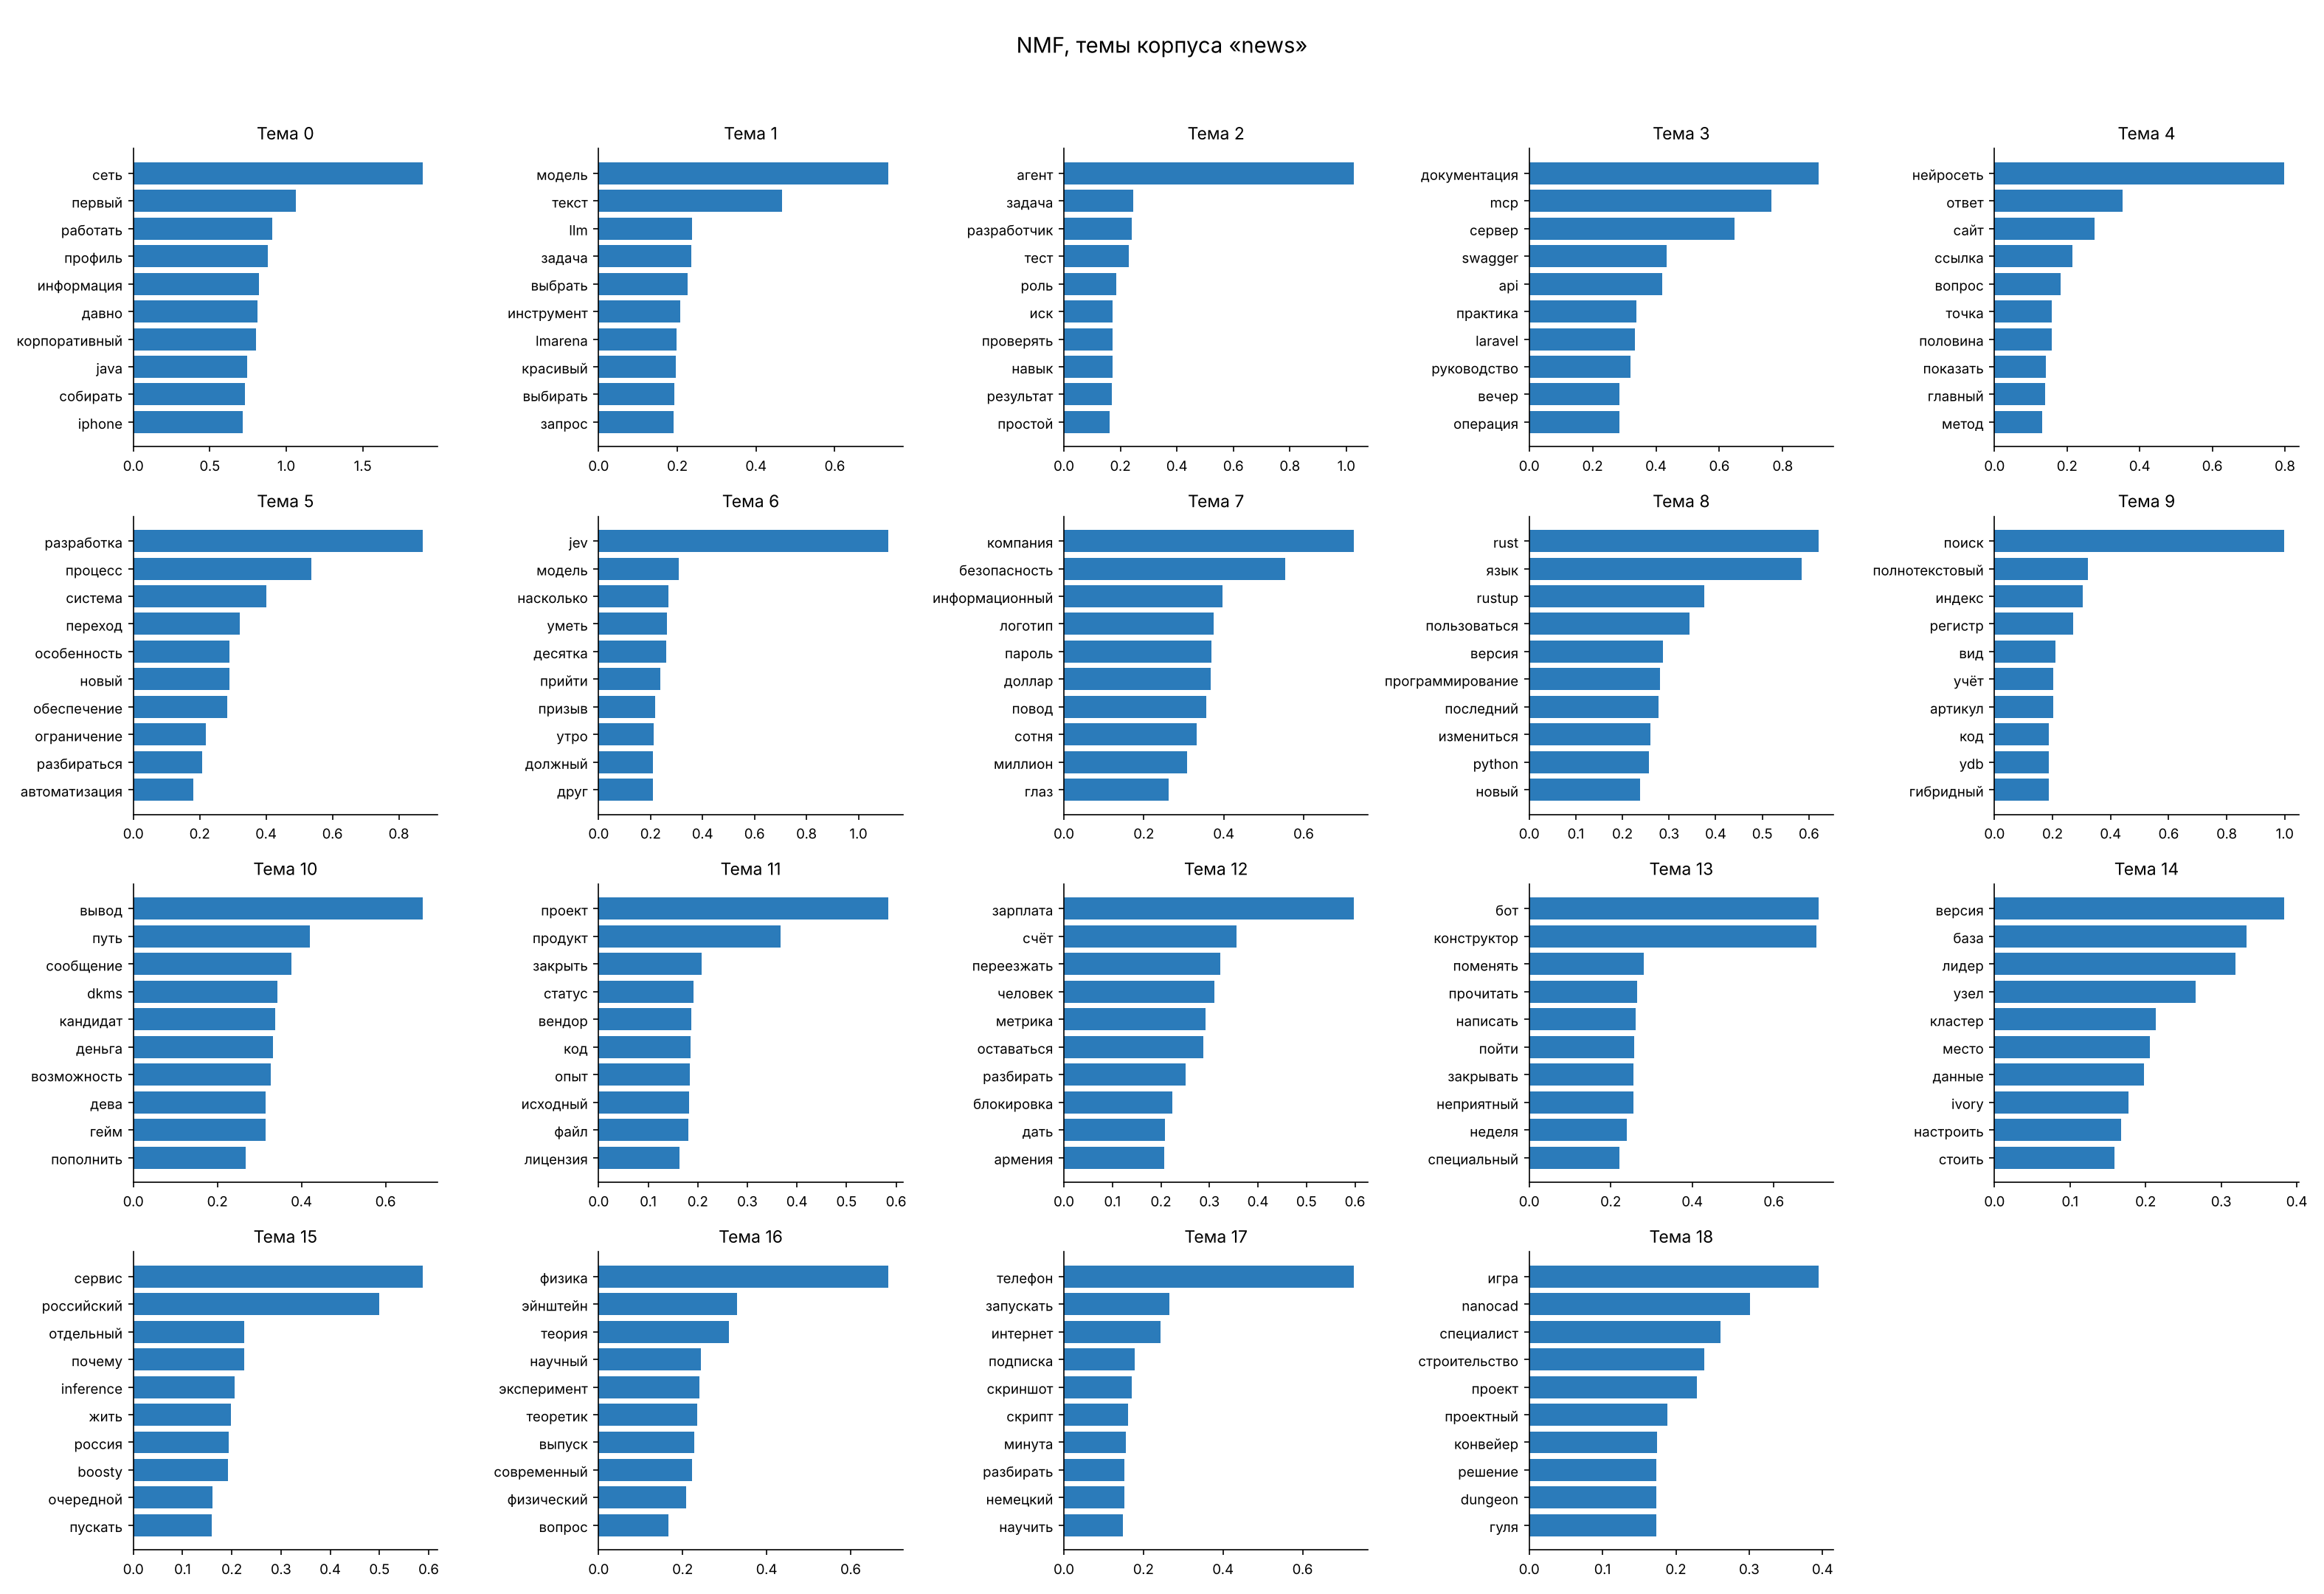

In [7]:
show("news_auto_topwords_nmf.png", width=1400)

## Ключевые слова с весами

Из JSON-выгрузки — то, что требуется третьим пунктом задания.

In [8]:
import json

result = json.loads((OUTPUT / "news_auto_topics.json").read_text(encoding="utf-8"))
for block in result["results"]:
    print(f"{block['method'].upper()}: тем {block['topics']}, coherence {block['coherence']:.4f}")
print()

nmf = next(block for block in result["results"] if block["method"] == "nmf")
for topic in nmf["keywords"][:6]:
    words = ", ".join(f"{item['word']} ({item['weight']:.3f})" for item in topic["words"][:6])
    print(f"  тема {topic['topic']}: {words}")

LDA: тем 17, coherence 0.3731
NMF: тем 19, coherence 0.4712

  тема 0: сеть (1.894), первый (1.061), работать (0.910), профиль (0.878), информация (0.823), давно (0.814)
  тема 1: модель (0.736), текст (0.466), llm (0.238), задача (0.235), выбрать (0.226), инструмент (0.207)
  тема 2: агент (1.026), задача (0.244), разработчик (0.241), тест (0.230), роль (0.185), иск (0.173)
  тема 3: документация (0.914), mcp (0.765), сервер (0.649), swagger (0.434), api (0.420), практика (0.337)
  тема 4: нейросеть (0.798), ответ (0.353), сайт (0.275), ссылка (0.215), вопрос (0.183), точка (0.157)
  тема 5: разработка (0.873), процесс (0.536), система (0.401), переход (0.321), особенность (0.289), новый (0.289)


## Распределение тем по документам

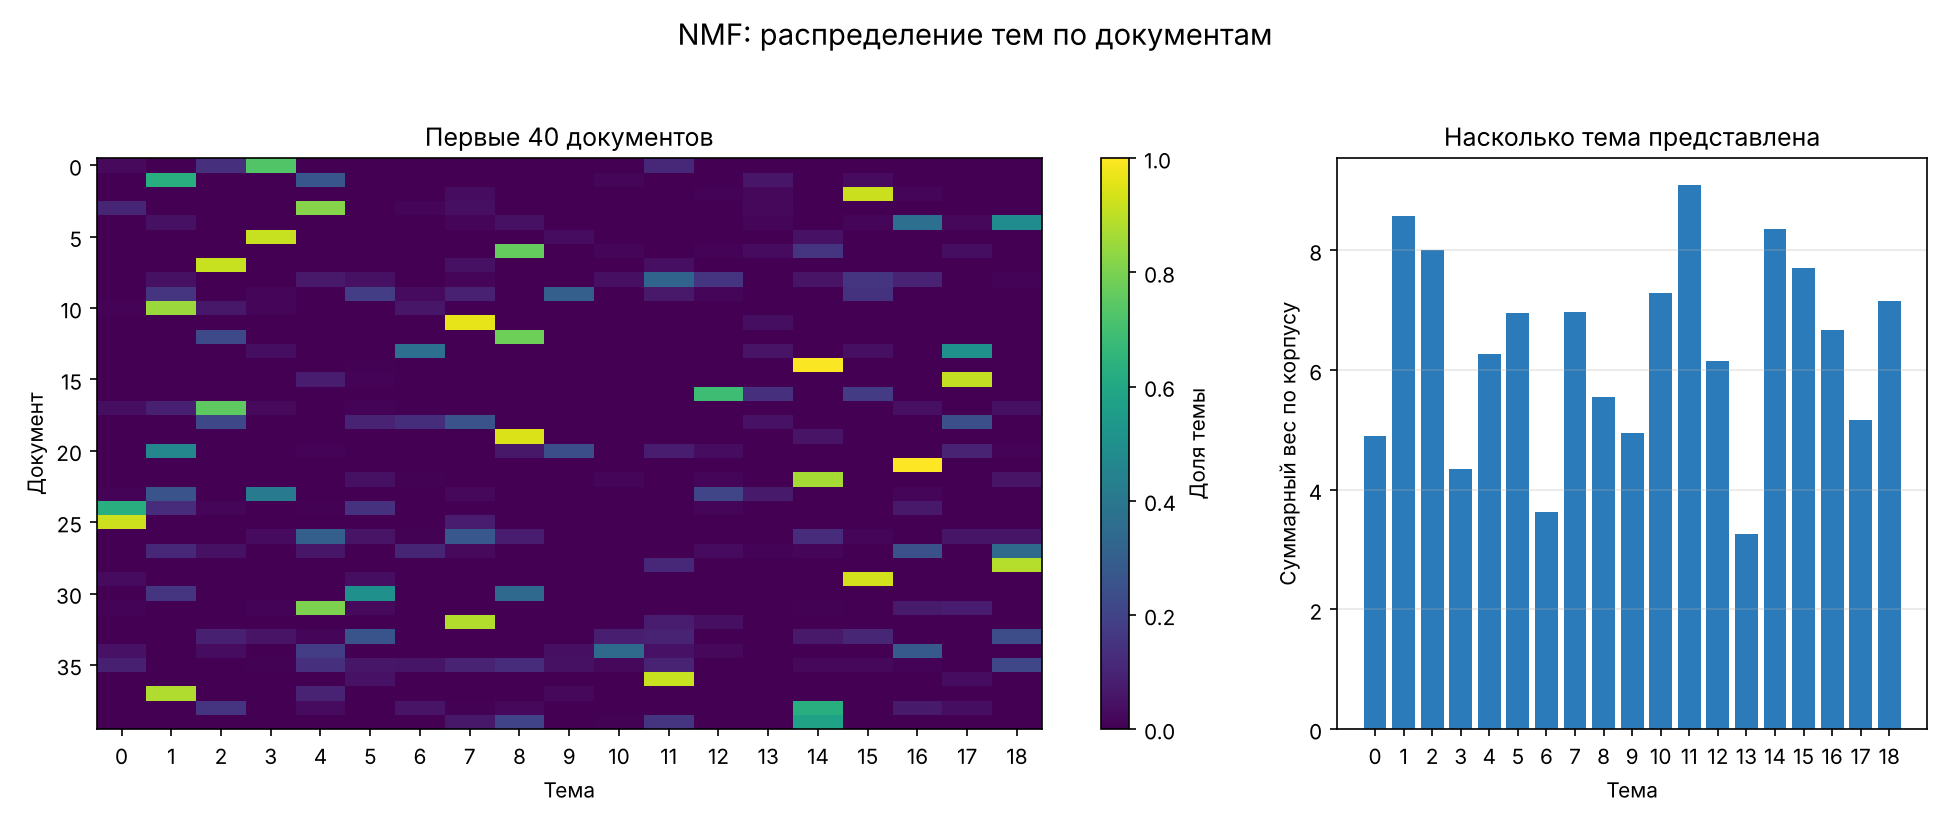

In [9]:
show("news_auto_documents_nmf.png", width=1200)

In [10]:
import csv

with (OUTPUT / "news_auto_documents_nmf.csv").open(encoding="utf-8-sig") as handle:
    rows = list(csv.DictReader(handle))

print("документов в выгрузке:", len(rows))
print()
for row in rows[:8]:
    print(f"  тема {row['главная тема']:>2} ({row['доля главной темы']})  {row['title'][:62]}")

документов в выгрузке: 121

  тема  3 (0.7273)  Вечер на код и месяц на всё остальное: свой MCP-сервер
  тема  1 (0.63)  Нейросети для 3D: как сгенерировать модель по тексту и фото
  тема 15 (0.9185)  Бусти.ру — или как зарубежная компания пытается оставаться рос
  тема  4 (0.8171)  Крошечная нейронная сеть без компьютера и калькулятора
  тема 18 (0.4871)  Как я создал СуперЗавуч — программу для генерации расписаний з
  тема  3 (0.9153)  Разбираемся с MCP на практике: сервер документации Swagger на 
  тема  8 (0.7634)  Typing в Python 3.11–3.14: что изменилось и как это использова
  тема  2 (0.9144)  Ускорение рутины в 10 раз: как мы внедрили навыки для ИИ-агент


## Облака слов

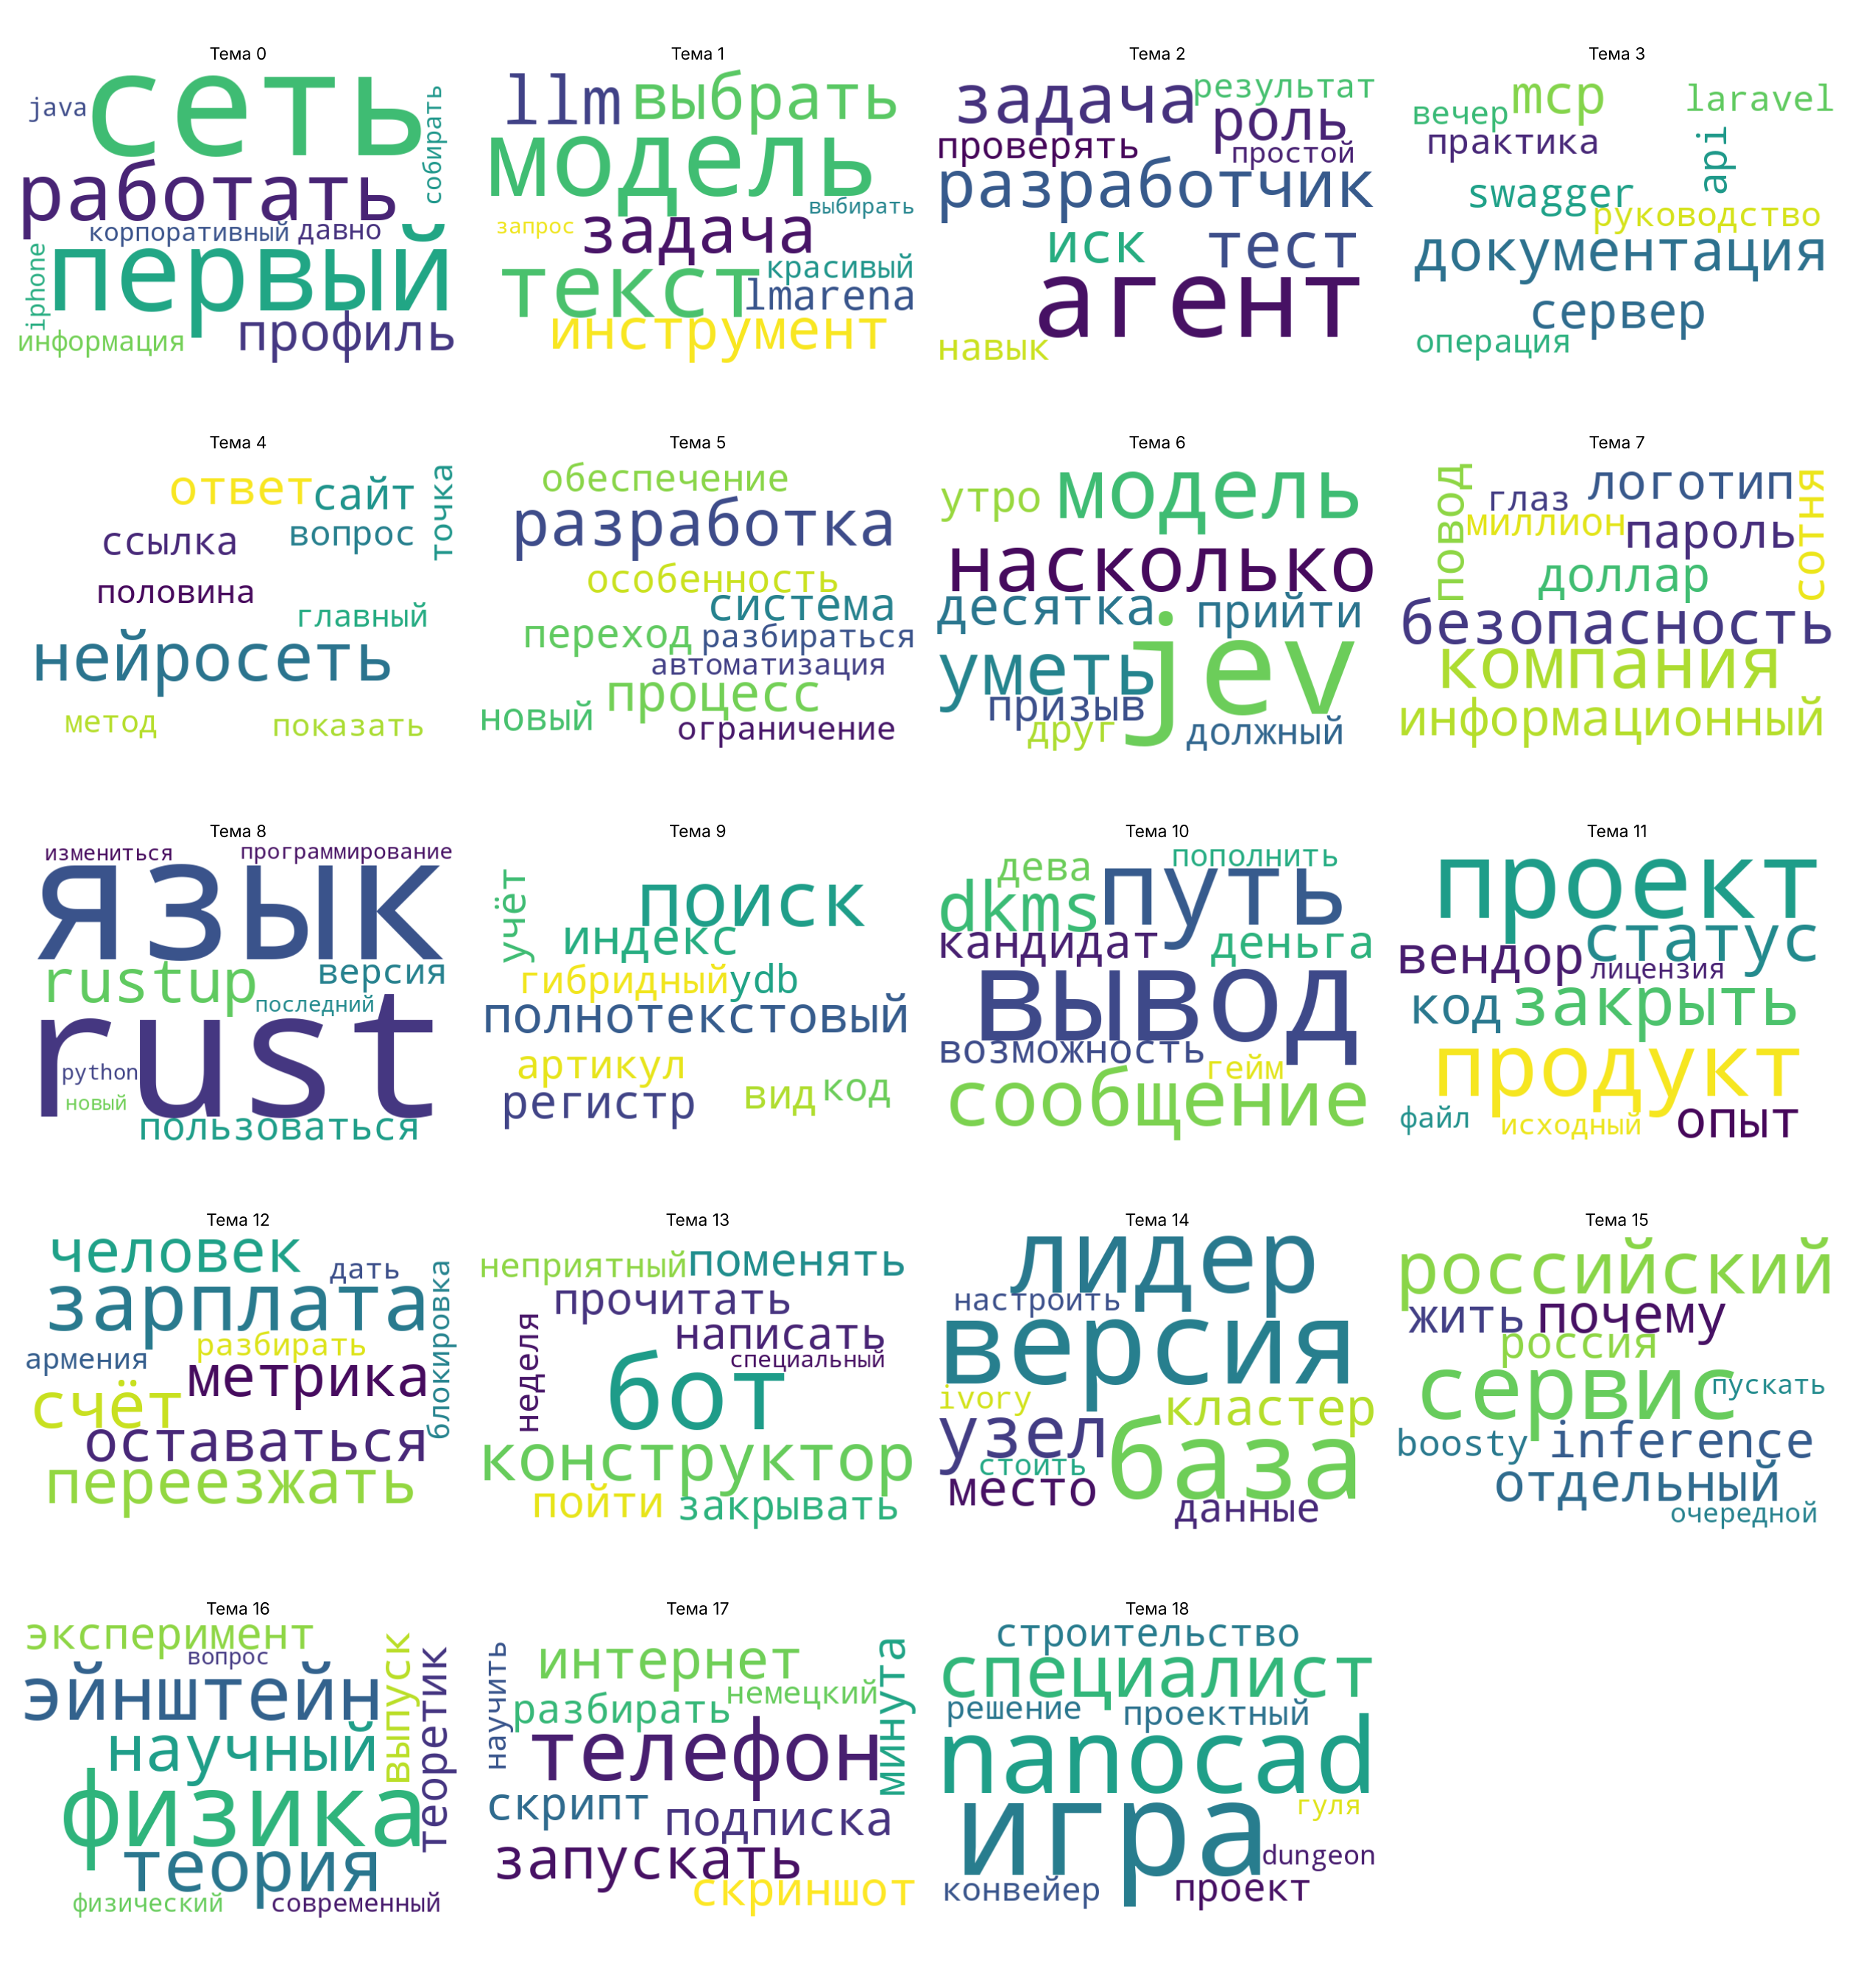

In [11]:
show("news_auto_wordcloud_nmf.png", width=1300)

## Сравнение LDA и NMF

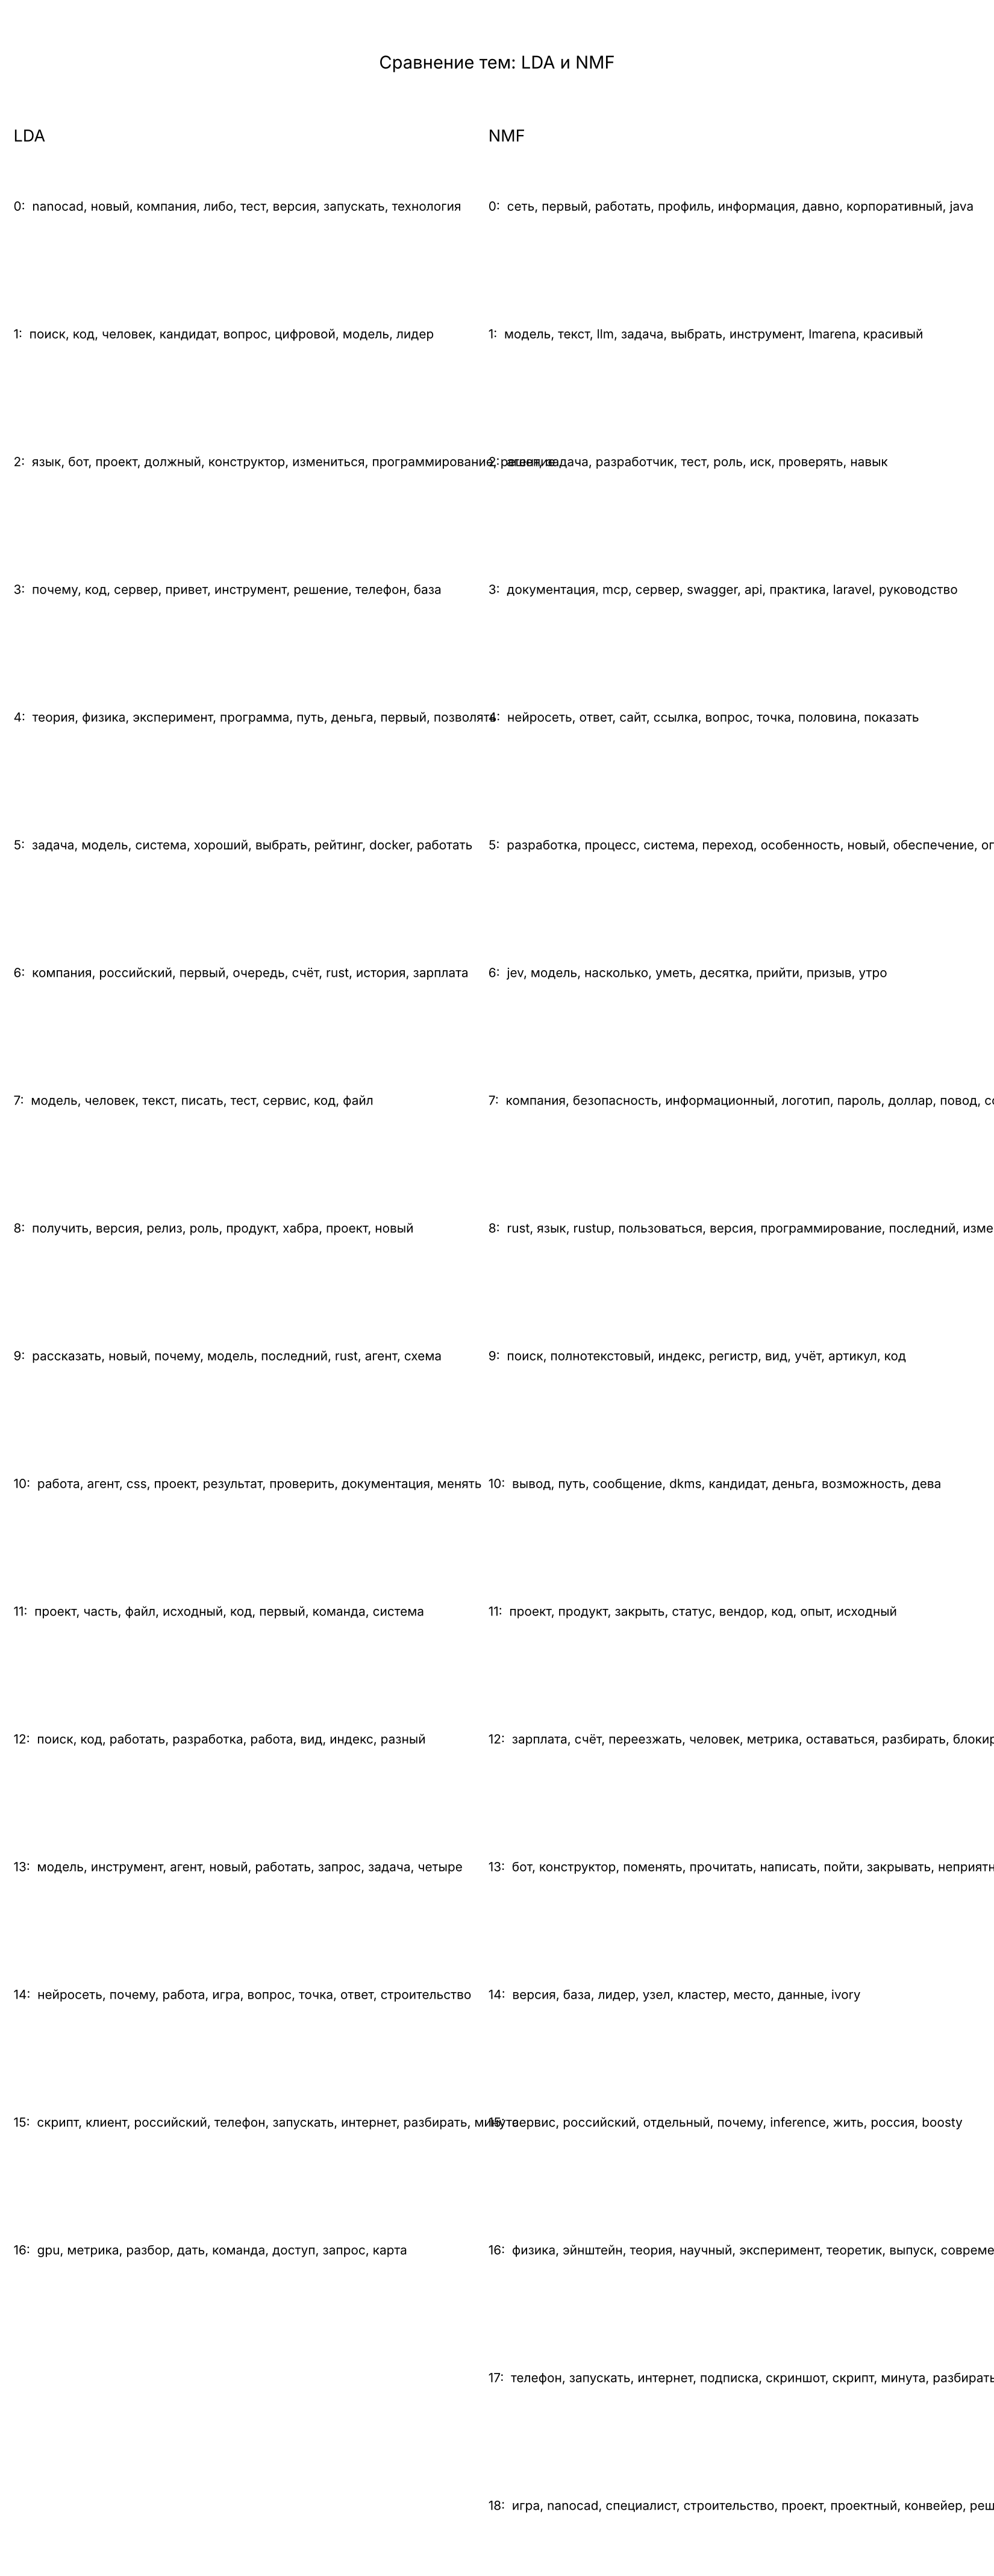

In [12]:
show("news_auto_compare.png", width=1100)

## Второй датасет: товары

In [13]:
run("topic_modeling.py", "--dataset", "products", "--method", "nmf",
    "--topics", "8", "--output", "product_categories", tail=10)

$ topic_modeling.py --dataset products --method nmf --topics 8 --output product_categories


Датасет: products
  документов: загружено 138, отброшено коротких 79, в работе 59
  словарь после фильтрации: 31 слов
  NMF: тем 8, coherence c_v = 0.7732
Результаты: /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab5/output
  product_categories_documents_nmf.csv
  product_categories_documents_nmf.png
  product_categories_topics.json
  product_categories_topwords_nmf.png
  product_categories_wordcloud_nmf.png


0

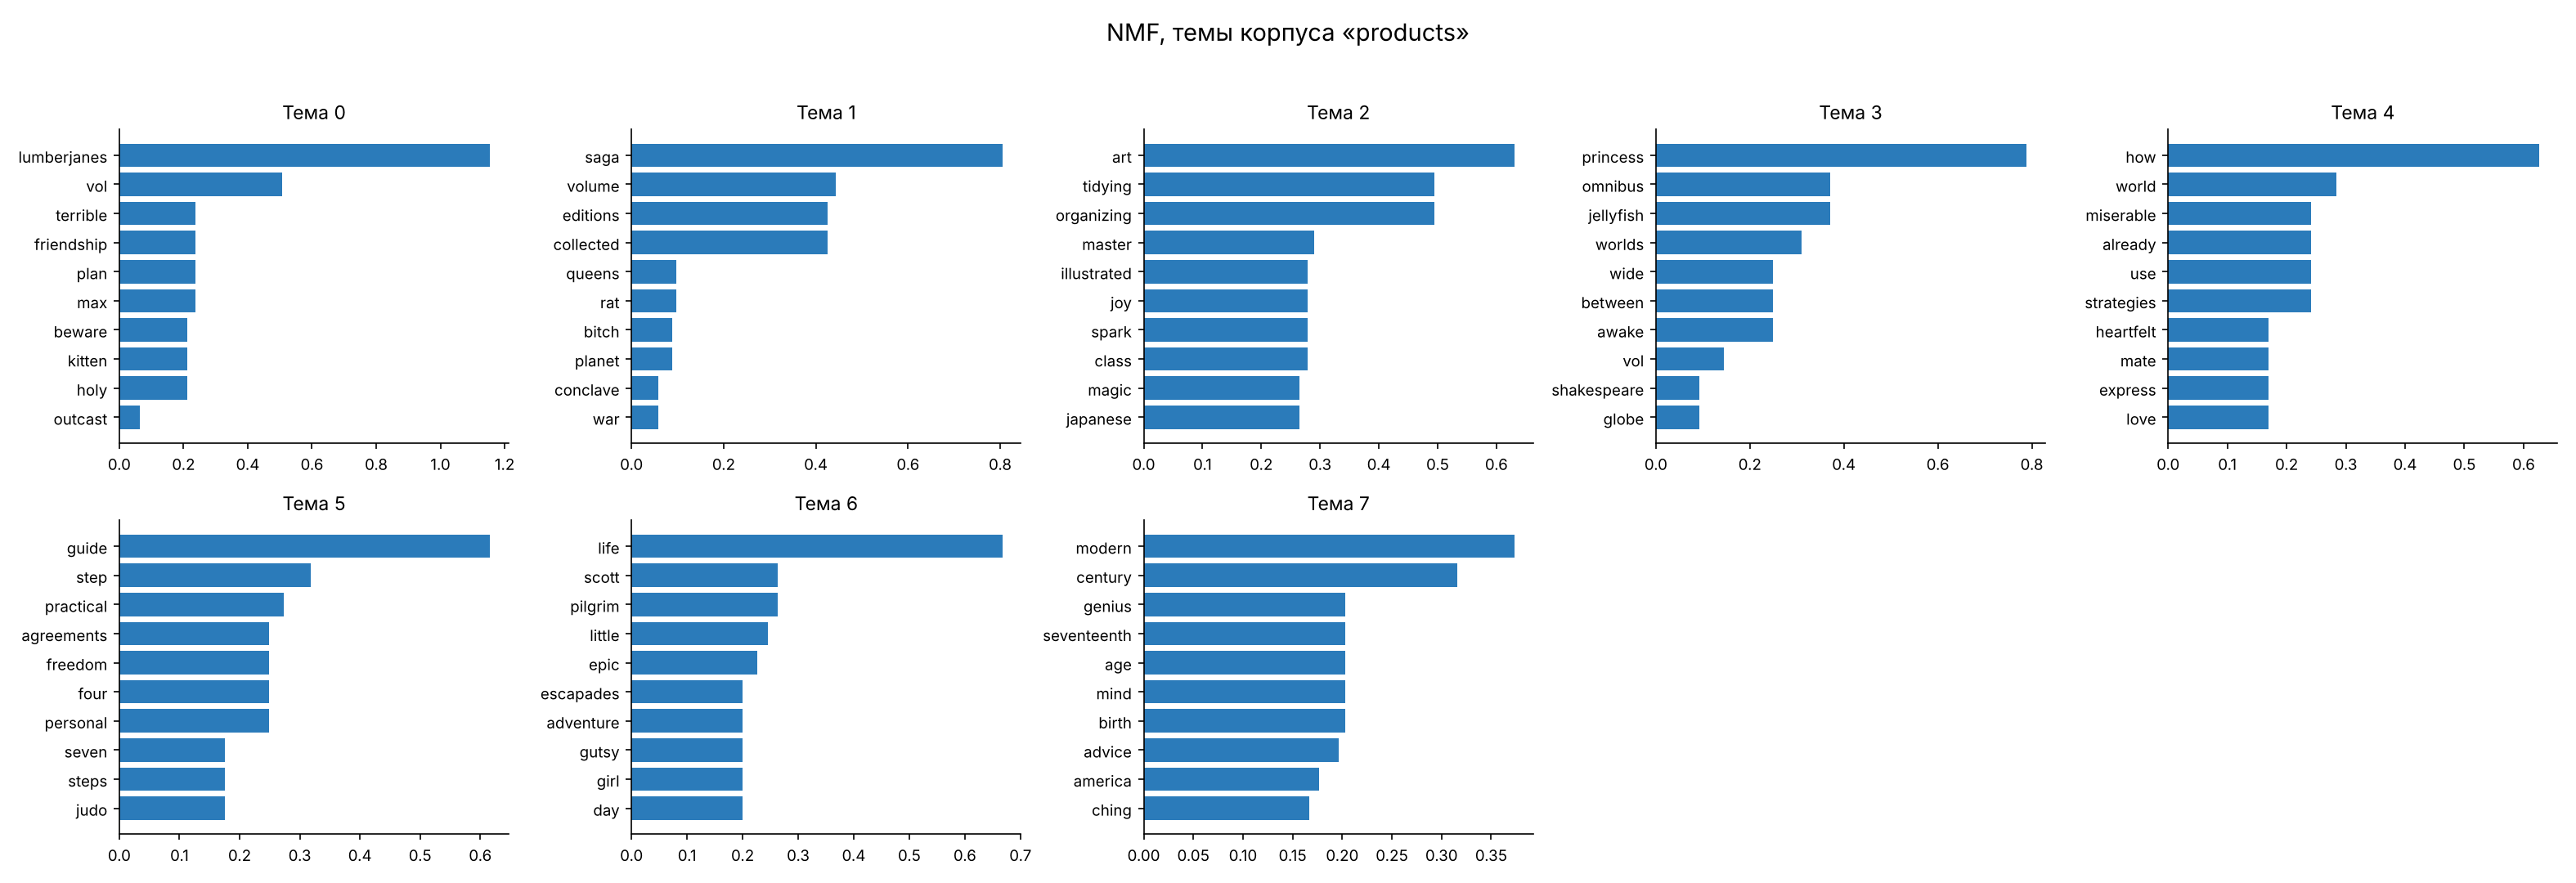

In [14]:
show("product_categories_topwords_nmf.png", width=1400)

---
# Задание 2: кластеризация городов по кухне

Города кодируются векторами частотности блюд: значение измерения — доля страниц
о кухне города, где это блюдо упомянуто. Дальше три метода кластеризации.

Сбор данных требует интернета. Если он есть, раскомментируйте первую строку —
она соберёт данные из Википедии в `data/city_dishes.json`. Без сбора используется
демонстрационный набор, и это будет видно в выводе.

In [15]:
# run("city_clustering.py", "--collect", tail=15)

data_file = LAB / "data" / "city_dishes.json"
if not data_file.exists():
    data_file = LAB / "data" / "demo_city_dishes.json"
print("используется:", data_file.name)

используется: demo_city_dishes.json


In [16]:
run("city_clustering.py", "--clusters", "4", "--output", "cities",
    "--data", data_file, tail=20)

$ city_clustering.py --clusters 4 --output cities --data /tmp/claude-0/-home-claude/37419b0e-7b34-5281-aca7-ee316eaa2693/scratchpad/project/lab5/data/demo_city_dishes.json


ВНИМАНИЕ: это демонстрационный набор, а не собранные данные.
Настоящие данные: python city_clustering.py --collect
Городов: 10, измерений (блюд): 47
  kmeans       : [0] Казань, Уфа | [1] Новосибирск, Хабаровск, Владивосток | [2] Пермь, Кунгур | [3] Петрозаводск, Москва, Санкт-Петербург
  hierarchical : [0] Новосибирск, Хабаровск, Владивосток | [1] Петрозаводск, Москва, Санкт-Петербург | [2] Казань, Уфа | [3] Пермь, Кунгур
  spectral     : [0] Петрозаводск, Москва, Санкт-Петербург | [1] Пермь, Кунгур | [2] Новосибирск, Хабаровск, Владивосток | [3] Казань, Уфа
  согласие hierarchical и kmeans: 1.00
  согласие hierarchical и spectral: 1.00
  согласие kmeans и spectral: 1.00
  методы согласны — разбиение устойчивое
  silhouette максимален при k = 6
  топ блюд кластера 0: чак-чак, эчпочмак, беляш, кыстыбый, бешбармак
  топ блюд кластера 1: строганина, красная икра, краб, папоротник, позы
  топ блюд кластера 2: пистики, посикунчики, шаньги, пиканы, кулебяка
  топ блюд кластера 3: шаурма, ух

0

Проекция городов на плоскость и проверка числа кластеров:

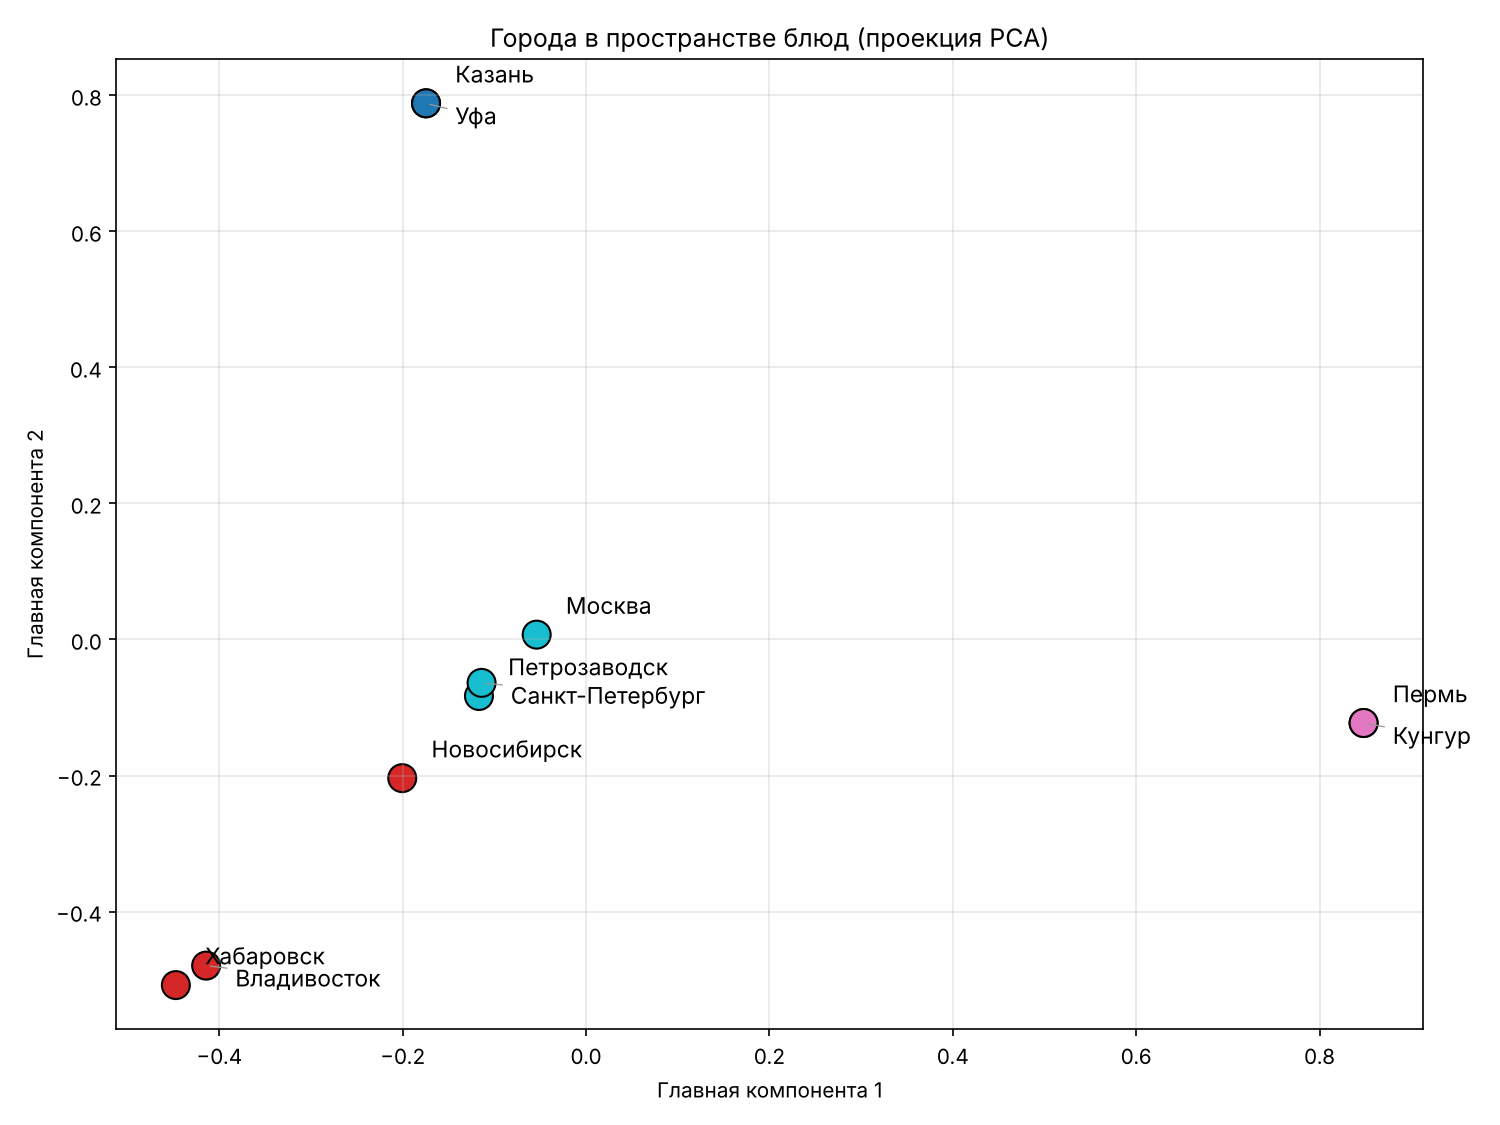

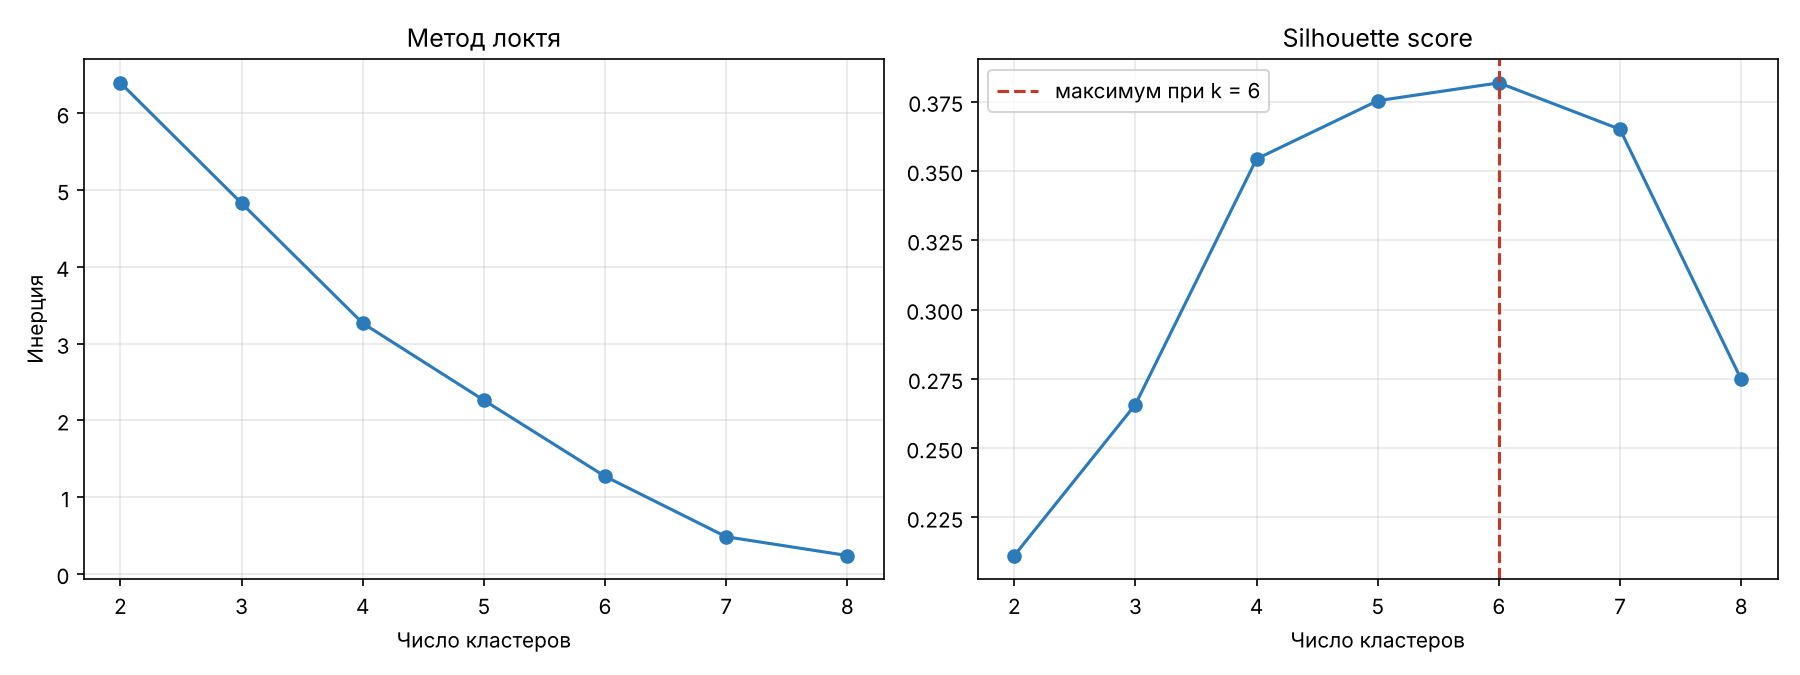

In [17]:
show("cities_clusters.png", width=1000)
show("cities_evaluation.png", width=1100)

In [18]:
report = json.loads((OUTPUT / "cities_clusters.json").read_text(encoding="utf-8"))

print("Согласие методов (индекс Rand, 1.0 — полное совпадение):")
for pair, score in report["agreement"].items():
    print(f"  {pair:28} {score:.2f}")
print()
print("Топ блюд по кластерам:")
for label, dishes in sorted(report["top_dishes"].items()):
    print(f"  кластер {label}: {', '.join(dishes)}")

Согласие методов (индекс Rand, 1.0 — полное совпадение):
  hierarchical и kmeans        1.00
  hierarchical и spectral      1.00
  kmeans и spectral            1.00

Топ блюд по кластерам:
  кластер 0: чак-чак, эчпочмак, беляш, кыстыбый, бешбармак
  кластер 1: строганина, красная икра, краб, папоротник, позы
  кластер 2: пистики, посикунчики, шаньги, пиканы, кулебяка
  кластер 3: шаурма, уха, корюшка, оливье, калитки


---
# Выводы

**NMF даёт более интерпретируемые темы, чем LDA.** На новостном корпусе coherence у NMF
стабильно выше на всём диапазоне K, и в топе тем видны осмысленные группы: документация
и API, полнотекстовый поиск, агенты и тестирование, нейросети. У LDA в тех же темах больше
частотных слов общего характера. Это совпадает с тем, что сказано в лекции: на коротких
текстах вероятностная модель хуже разделяет темы. NMF ещё и считается быстрее — подбор K
по всему диапазону занимает секунды против десятков секунд у LDA.

**Максимум coherence не означает лучшее число тем.** Формальный максимум пришёлся на
K = 17 для LDA и K = 19 для NMF, но при 121 документе это means по 6–7 документов на тему:
модель дробит корпус, а не находит структуру. График coherence растёт почти монотонно,
то есть метрика поощряет дробление. Практический выбор — K от 8 до 10, где график выходит
на полку, а темы ещё можно назвать словами. Именно поэтому в лекции сказано не гнаться
за максимумом слепо.

**Качество тем упирается в стоп-слова.** После первого прогона в топе тем оказались «это»,
«мочь», «самый» — пришлось дополнять список стоп-слов общеупотребительными глаголами
и местоимениями, которые остаются после лемматизации. Без этого несколько тем вырождаются
в наборы служебных слов.

**Корпус товаров слабее новостного.** Названия товаров — это пять-семь слов, и значительная
часть записей отсеивается как слишком короткие. Темы по товарам получаются в основном
по брендам и типам устройств. Описания с карточек товара, которые собирает доработанный
паук практики 2, заметно улучшают картину — на одних названиях тематическое моделирование
работает плохо.

**Кластеризация городов устойчива.** Три метода — k-means, иерархическая и спектральная —
дали одно и то же разбиение, индекс Rand между всеми парами равен 1.0. Это главный
признак того, что структура в данных есть, а не придумана методом. Содержательная проверка
сходится: Казань и Уфа вместе (татарская и башкирская кухни близки), Пермь и Кунгур вместе
(уральская), Хабаровск и Владивосток вместе (дальневосточная рыба и морепродукты).
Топ-блюда кластеров читаются без расшифровки.

**Общие блюда приходится исключать.** Борщ, блины и пельмени упоминаются почти везде
с одинаковой частотой, не несут различающей информации и размывают кластеры. Они помечены
в словаре и отбрасываются при построении матрицы. L2-нормализация строк нужна по той же
причине: без неё город, про который нашлось больше страниц, оказывается «ближе» ко всем
сразу просто из-за масштаба, а не из-за кухни.